In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
import docx
import textract
from pypdf import PdfReader
from collections import Counter
import zipfile

In [28]:
dataset_path = "dataset"

data = []

for root, dirs, files in os.walk(dataset_path):

    for file in files:

        file_path = os.path.join(root, file)

        category = os.path.basename(root)

        data.append({
            "filename": file,
            "filepath": file_path,
            "category": category
        })

df = pd.DataFrame(data)
df

,filename,filepath,category
0,Peoplesoft Admin_G Ananda Rayudu.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft\P...,Peoplesoft
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft Resume
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft Resume
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft Resume
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft Resume
...,...,...,...
75,Sri Krishna S_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Sri ...,workday
76,Srikanth-Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\Srik...,workday
77,SSKumar_Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\SSKu...,workday
78,Venkateswarlu B_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Venk...,workday


In [29]:
df.shape

(80, 3)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   filename  80 non-null     object
 1   filepath  80 non-null     object
 2   category  80 non-null     object
dtypes: object(3)
memory usage: 2.0+ KB


In [31]:
df['category'] = df['category'].replace({
    'Peoplesoft Resume': 'Peoplesoft',
    'workday': 'Workday'
})

In [32]:
df

,filename,filepath,category
0,Peoplesoft Admin_G Ananda Rayudu.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft\P...,Peoplesoft
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft
...,...,...,...
75,Sri Krishna S_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Sri ...,Workday
76,Srikanth-Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\Srik...,Workday
77,SSKumar_Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\SSKu...,Workday
78,Venkateswarlu B_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Venk...,Workday


In [33]:
df.isnull().sum()

filename    0
filepath    0
category    0
dtype: int64

In [34]:
df['category'].value_counts()

category
React Developer    24
Peoplesoft         21
Workday            21
SQL Developer      14
Name: count, dtype: int64

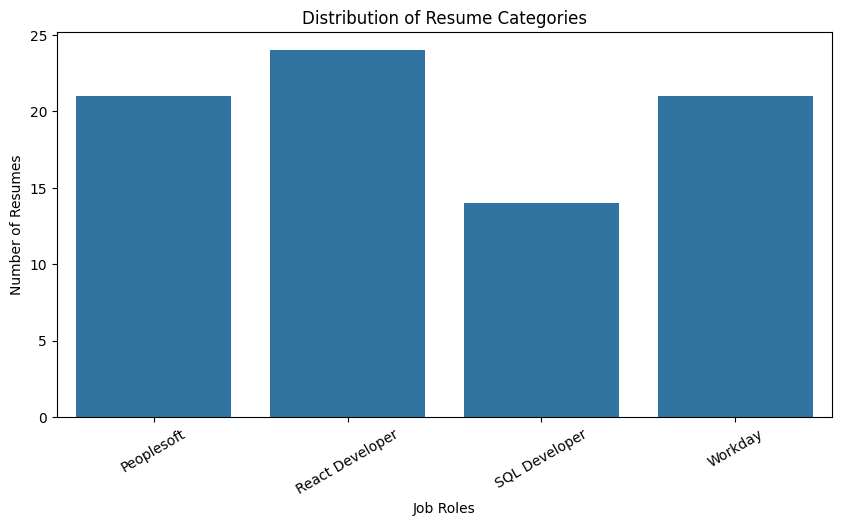

In [35]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='category')

plt.title("Distribution of Resume Categories")
plt.xlabel("Job Roles")
plt.ylabel("Number of Resumes")
plt.xticks(rotation=30)

plt.show()

In [36]:
df.duplicated().sum()

np.int64(0)

In [37]:
df['filename'].duplicated().sum()

np.int64(0)

In [38]:
df.describe(include='all')

,filename,filepath,category
count,80,80,80
unique,80,80,4
top,Peoplesoft Admin_G Ananda Rayudu.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft\P...,React Developer
freq,1,1,24


In [39]:


def extract_text(file_path):

    extension = os.path.splitext(file_path)[1].lower()

    try:

        if extension == '.docx':

            # Check whether the DOCX structure is valid
            with zipfile.ZipFile(file_path, 'r') as z:

                if 'word/document.xml' not in z.namelist():
                    print("Invalid DOCX structure:", file_path)
                    return ""

            document = docx.Document(file_path)

            text = []

            for paragraph in document.paragraphs:
                text.append(paragraph.text)

            for table in document.tables:
                for row in table.rows:
                    for cell in row.cells:
                        text.append(cell.text)

            return " ".join(text)

        elif extension == '.doc':

            return textract.process(
                file_path,
                extension='doc'
            ).decode('utf-8', errors='ignore')

        elif extension == '.pdf':

            reader = PdfReader(file_path)

            return " ".join(
                page.extract_text() or ""
                for page in reader.pages
            )

        return ""

    except Exception as e:

        print("Extraction failed:", file_path)
        print("Reason:", e)

        return ""

In [40]:
print("Total files:", len(df))

print(df['filepath'].str.lower().str.endswith('.doc').sum(), "DOC files")
print(df['filepath'].str.lower().str.endswith('.docx').sum(), "DOCX files")
print(df['filepath'].str.lower().str.endswith('.pdf').sum(), "PDF files")

Total files: 80
26 DOC files
53 DOCX files
1 PDF files


In [41]:
valid_files = df[
    df['filepath'].str.lower().str.endswith('.docx')
]

for path in valid_files['filepath']:

    text = extract_text(path)

    if len(text) > 0:
        print("Successfully extracted:", path)
        print(text[:500])
        break

Invalid DOCX structure: dataset\P637 Dataset\Resumes_Docx\Peoplesoft\Peoplesoft Admin_G Ananda Rayudu.docx
Successfully extracted: dataset\P637 Dataset\Resumes_Docx\Peoplesoft Resume\Peoplesoft Admin_AnubhavSingh.docx
  Anubhav Kumar Singh		    To work in a globally competitive environment on    challenging assignments that shall yield the    twin benefits of the job satisfaction and a steady-paced    professional growth.                Professional Experience   06/2019 - Current	HCL										 			Current Role: System Admin Offshore 			Skills : Shell Scripting, Linux , PeopleSoft Administration , Github  Managing PeopleSoft HCM and PeopleSoft FSCM production environments along with support environments install


In [42]:
from tqdm.notebook import tqdm

resume_texts = []

for path in tqdm(df['filepath'], desc="Extracting resumes"):

    text = extract_text(path)

    resume_texts.append(text)

df['resume_text'] = resume_texts

Extracting resumes:   0%|          | 0/80 [00:00<?, ?it/s]

Invalid DOCX structure: dataset\P637 Dataset\Resumes_Docx\Peoplesoft\Peoplesoft Admin_G Ananda Rayudu.docx


In [43]:
df['text_length'] = df['resume_text'].str.len()

print("Total resumes:", len(df))

print("Successfully extracted:",
      (df['text_length'] > 0).sum())

print("Failed extraction:",
      (df['text_length'] == 0).sum())

Total resumes: 80
Successfully extracted: 79
Failed extraction: 1


In [44]:
df[['filename', 'category', 'resume_text']].head()

,filename,category,resume_text
0,Peoplesoft Admin_G Ananda Rayudu.docx,Peoplesoft,
1,Peoplesoft Admin_AnubhavSingh.docx,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...
2,Peoplesoft Admin_G Ananda Rayudu.doc,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...
3,Peoplesoft Admin_Gangareddy.doc,Peoplesoft,PeopleSoft Database Administrator\n ...
4,Peoplesoft Admin_Murali.docx,Peoplesoft,Murali Experience Summary I have 6 years of...


In [45]:
# Remove null values
df = df.dropna(subset=['resume_text'])

# Remove empty resumes
df = df[df['resume_text'].str.strip() != '']

# Remove duplicate resumes
df = df.drop_duplicates(subset=['resume_text'])

In [46]:
df

,filename,filepath,category,resume_text,text_length
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...,7447
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,8443
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,PeopleSoft Database Administrator\n ...,7062
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Murali Experience Summary I have 6 years of...,4594
5,Peoplesoft Admin_Priyanka Ramadoss.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",5374
...,...,...,...,...,...
75,Sri Krishna S_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Sri ...,Workday,\tWorkday Integration Consultant\n\nName ...,7239
76,Srikanth-Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\Srik...,Workday,Seeking suitable positions in Workday HCM as ...,6547
77,SSKumar_Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\SSKu...,Workday,WORKDAY | HCM | FCM Name \t\t: Kumar S.S Role...,8117
78,Venkateswarlu B_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Venk...,Workday,Venkateswarlu.B\t\t\t\t\t\t\t\tWorkday Consult...,6857


In [47]:
df.tail()

,filename,filepath,category,resume_text,text_length
75,Sri Krishna S_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Sri ...,Workday,\tWorkday Integration Consultant\n\nName ...,7239
76,Srikanth-Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\Srik...,Workday,Seeking suitable positions in Workday HCM as ...,6547
77,SSKumar_Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\SSKu...,Workday,WORKDAY | HCM | FCM Name \t\t: Kumar S.S Role...,8117
78,Venkateswarlu B_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Venk...,Workday,Venkateswarlu.B\t\t\t\t\t\t\t\tWorkday Consult...,6857
79,Vinay Kumar_Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\Vina...,Workday,...,5089


In [48]:
df['word_count'] = df['resume_text'].apply(
    lambda text: len(str(text).split())
)

In [49]:
df.head()

,filename,filepath,category,resume_text,text_length,word_count
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...,7447,963
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,8443,1053
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,PeopleSoft Database Administrator\n ...,7062,835
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Murali Experience Summary I have 6 years of...,4594,619
5,Peoplesoft Admin_Priyanka Ramadoss.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",5374,717


In [50]:
df[df['word_count'] > 0]['word_count'].describe()

count      79.000000
mean      722.670886
std       446.621584
min       200.000000
25%       414.000000
50%       602.000000
75%       906.000000
max      2682.000000
Name: word_count, dtype: float64

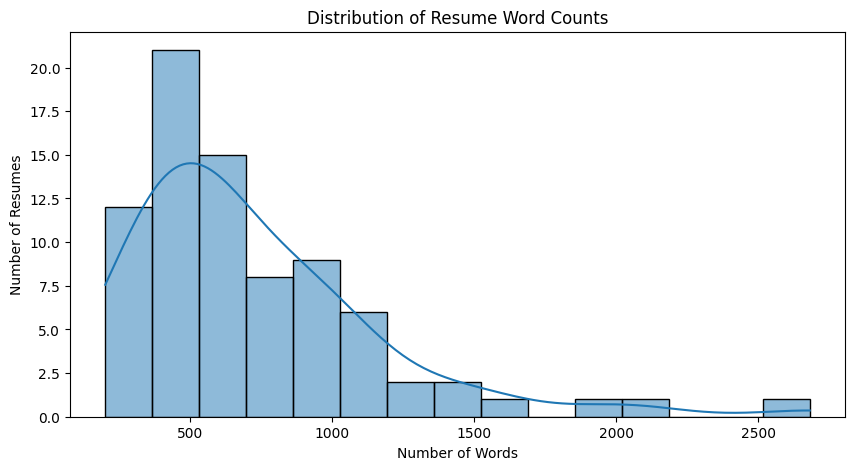

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['word_count'] > 0],
    x='word_count',
    bins=15,
    kde=True
)

plt.title("Distribution of Resume Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Resumes")

plt.show()

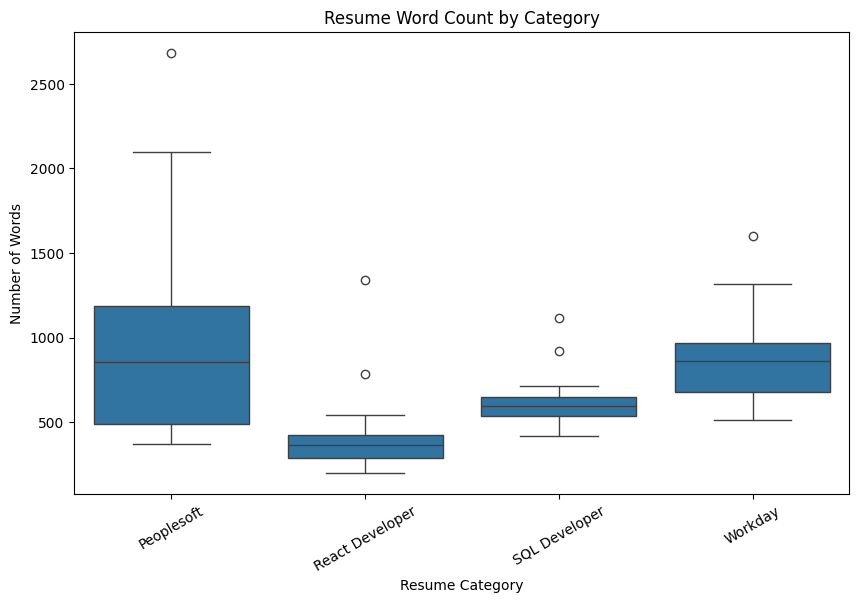

In [52]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df[df['word_count'] > 0],
    x='category',
    y='word_count'
)

plt.title("Resume Word Count by Category")
plt.xlabel("Resume Category")
plt.ylabel("Number of Words")

plt.xticks(rotation=30)

plt.show()

In [53]:
df[df['word_count'] > 0].groupby('category')['word_count'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
category,,,,,
Peoplesoft,20,996.700000,855.5,371,2682
React Developer,24,411.208333,363.5,200,1340
SQL Developer,14,637.928571,598.0,421,1115
Workday,21,874.142857,861.0,511,1601


In [54]:
#finding the most frequently occured words
from collections import Counter
import re

all_text = " ".join(
    df.loc[df['word_count'] > 0, 'resume_text']
)

words = re.findall(
    r'\b[a-zA-Z]+\b',
    all_text.lower()
)

word_counts = Counter(words)

print(word_counts.most_common(30))

[('and', 2883), ('the', 1417), ('in', 1315), ('to', 1141), ('of', 1043), ('on', 685), ('for', 684), ('experience', 584), ('peoplesoft', 451), ('with', 430), ('workday', 428), ('application', 416), ('as', 409), ('using', 395), ('server', 359), ('a', 344), ('data', 335), ('reports', 325), ('project', 323), ('from', 316), ('sql', 281), ('business', 273), ('database', 246), ('web', 245), ('process', 236), ('worked', 220), ('knowledge', 210), ('client', 198), ('involved', 191), ('tools', 190)]


In [55]:
#after removing the stop worsds
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

all_text = " ".join(
    df.loc[df['word_count'] > 0, 'resume_text']
).lower()

words = re.findall(r'\b[a-zA-Z]+\b', all_text)

filtered_words = [
    word for word in words
    if word not in ENGLISH_STOP_WORDS
]

filtered_counts = Counter(filtered_words)

print(filtered_counts.most_common(30))

[('experience', 584), ('peoplesoft', 451), ('workday', 428), ('application', 416), ('using', 395), ('server', 359), ('data', 335), ('reports', 325), ('project', 323), ('sql', 281), ('business', 273), ('database', 246), ('web', 245), ('process', 236), ('worked', 220), ('knowledge', 210), ('client', 198), ('involved', 191), ('tools', 190), ('integrations', 189), ('integration', 183), ('like', 180), ('support', 178), ('hcm', 177), ('development', 169), ('good', 165), ('team', 164), ('creating', 164), ('skills', 163), ('working', 159)]


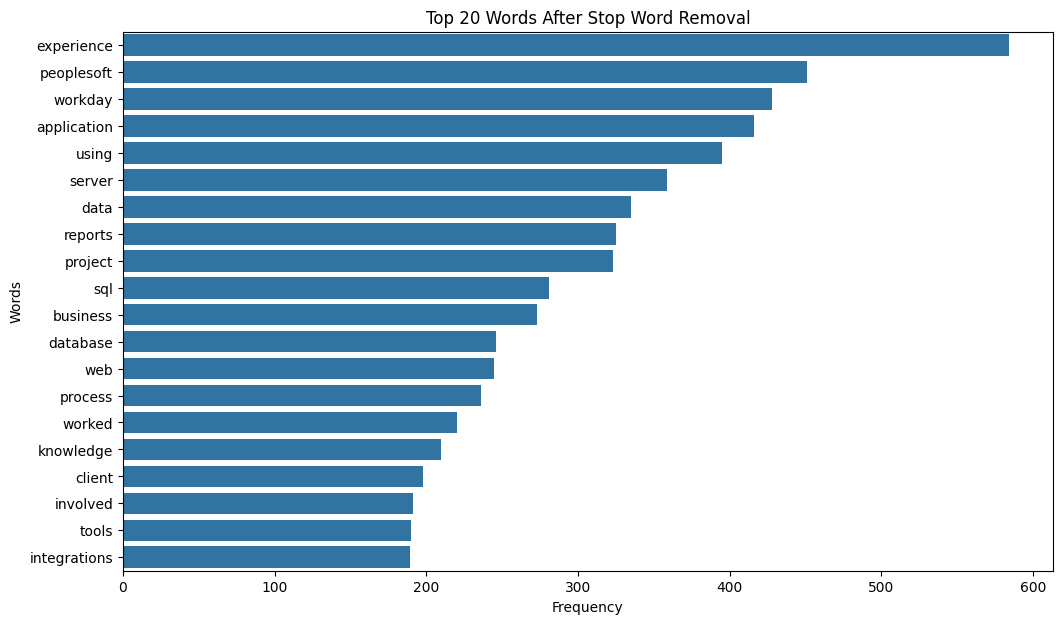

In [56]:
top_words = filtered_counts.most_common(20)

word_df = pd.DataFrame(
    top_words,
    columns=['word', 'frequency']
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=word_df,
    x='frequency',
    y='word'
)

plt.title("Top 20 Words After Stop Word Removal")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

In [57]:
for category in df['category'].unique():

    category_text = " ".join(
        df.loc[
            (df['category'] == category) &
            (df['word_count'] > 0),
            'resume_text'
        ].astype(str)
    ).lower()

    words = re.findall(
        r'\b[a-zA-Z]+\b',
        category_text
    )

    filtered_words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS
    ]

    word_counts = Counter(filtered_words)

    print("\nCategory:", category)
    print(word_counts.most_common(20))


Category: Peoplesoft
[('peoplesoft', 421), ('application', 307), ('server', 246), ('experience', 228), ('database', 164), ('servers', 146), ('process', 142), ('people', 133), ('tools', 118), ('web', 116), ('project', 114), ('oracle', 114), ('domains', 110), ('scheduler', 104), ('data', 93), ('reports', 85), ('support', 83), ('fscm', 82), ('environment', 81), ('production', 79)]

Category: React Developer
[('react', 144), ('js', 117), ('using', 90), ('experience', 90), ('project', 82), ('web', 73), ('javascript', 64), ('developer', 63), ('knowledge', 59), ('html', 56), ('skills', 53), ('application', 53), ('ui', 53), ('technologies', 48), ('design', 47), ('team', 46), ('good', 43), ('development', 43), ('used', 41), ('bootstrap', 40)]

Category: SQL Developer
[('sql', 227), ('data', 125), ('server', 107), ('experience', 104), ('using', 82), ('reports', 62), ('database', 62), ('functions', 61), ('project', 53), ('queries', 50), ('tables', 48), ('business', 45), ('knowledge', 45), ('proc

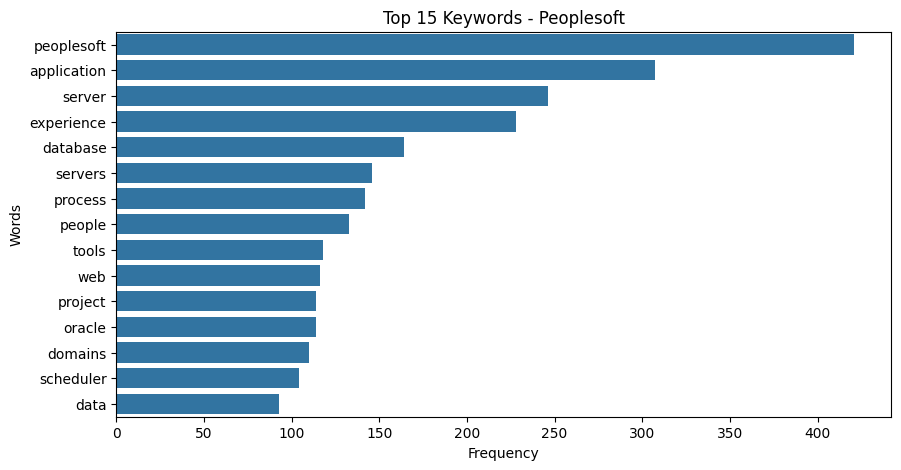

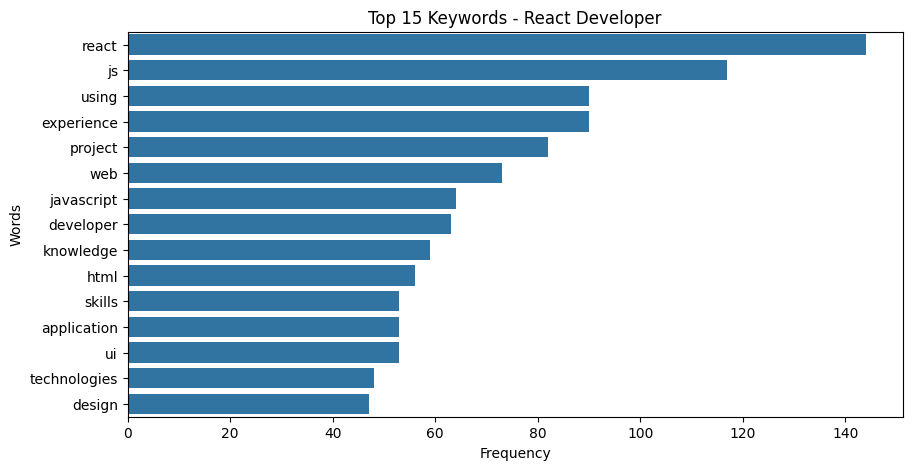

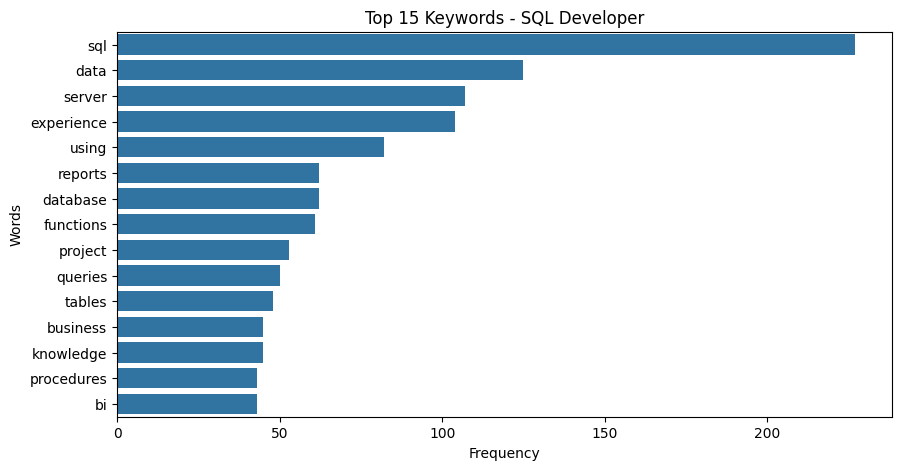

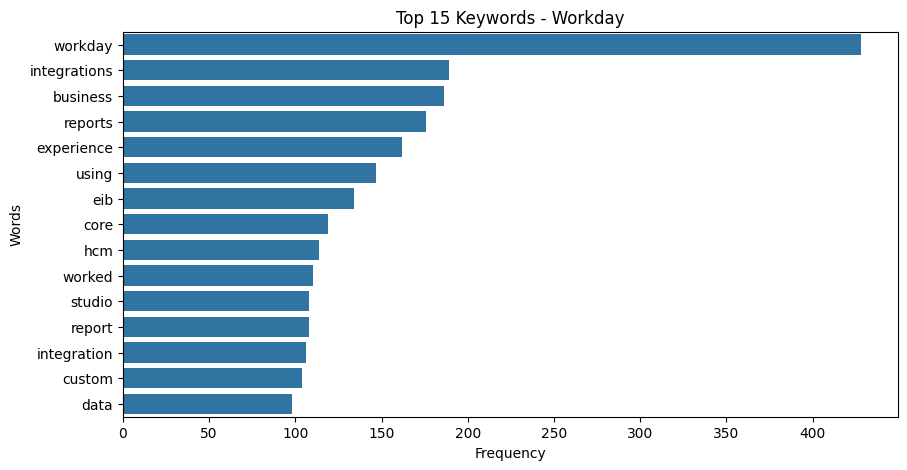

In [58]:
for category in df['category'].unique():

    category_text = " ".join(
        df.loc[
            (df['category'] == category) &
            (df['word_count'] > 0),
            'resume_text'
        ].astype(str)
    ).lower()

    words = re.findall(r'\b[a-zA-Z]+\b', category_text)

    filtered_words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS
    ]

    word_counts = Counter(filtered_words)

    top_words = word_counts.most_common(15)

    word_df = pd.DataFrame(
        top_words,
        columns=['word', 'frequency']
    )

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=word_df,
        x='frequency',
        y='word'
    )

    plt.title(f"Top 15 Keywords - {category}")
    plt.xlabel("Frequency")
    plt.ylabel("Words")

    plt.show()

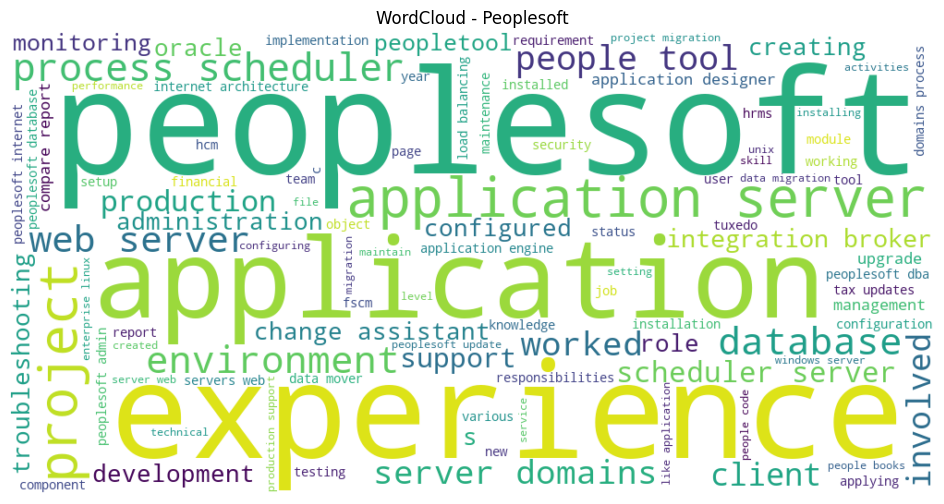

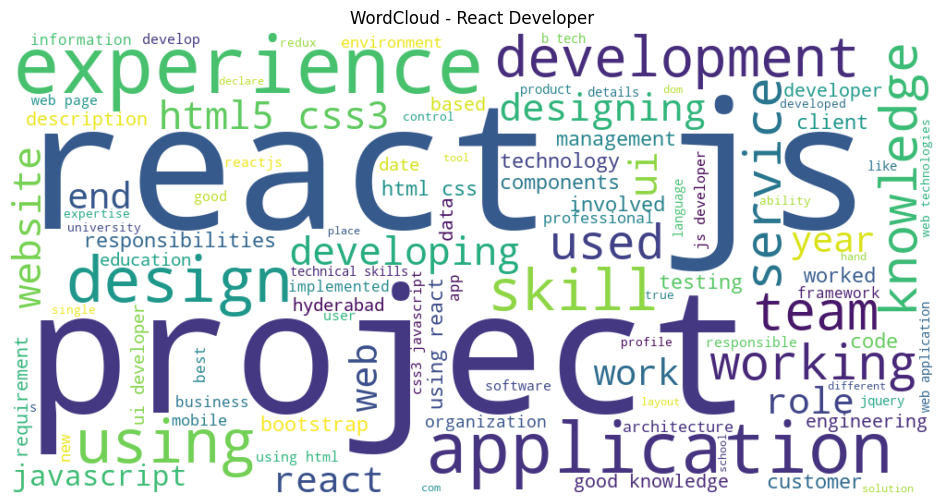

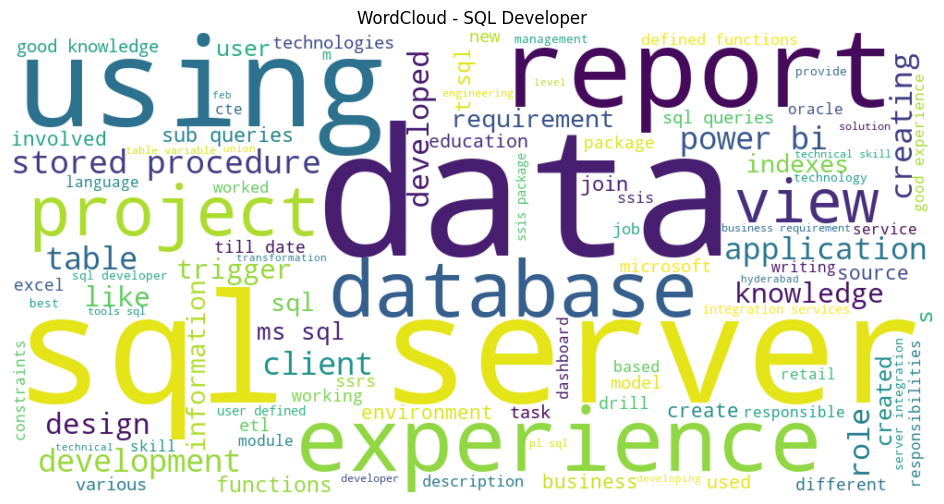

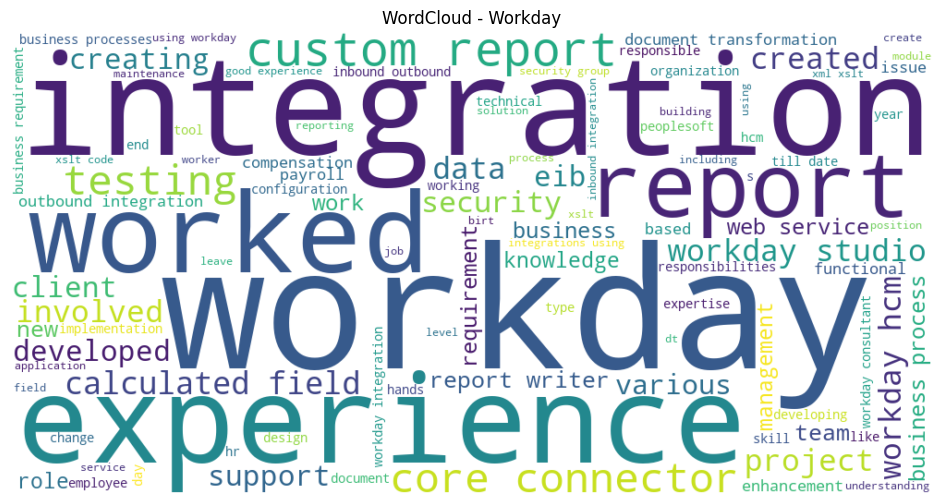

In [59]:
from wordcloud import WordCloud

for category in df['category'].unique():

    category_text = " ".join(
        df.loc[
            (df['category'] == category) &
            (df['word_count'] > 0),
            'resume_text'
        ].astype(str)
    ).lower()

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color='white',
        stopwords=ENGLISH_STOP_WORDS,
        max_words=100
    ).generate(category_text)

    plt.figure(figsize=(12, 6))

    plt.imshow(wordcloud, interpolation='bilinear')

    plt.axis('off')

    plt.title(f"WordCloud - {category}")

    plt.show()

In [60]:
df_model = df[
    df['resume_text'].notna() &
    (df['resume_text'].str.strip() != '')
].copy()

print("Original dataset:", len(df))
print("Usable resumes:", len(df_model))

Original dataset: 79
Usable resumes: 79


In [61]:
df_model['cleaned_text'] = (
    df_model['resume_text'].str.lower()
)

In [62]:
df_model.head()

,filename,filepath,category,resume_text,text_length,word_count,cleaned_text
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...,7447,963,anubhav kumar singh\t\t to work in a glob...
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,8443,1053,\n\n\n\n\n\n\t\n\nprofile summary:\t\t\t\t\t\t...
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,PeopleSoft Database Administrator\n ...,7062,835,peoplesoft database administrator\n ...
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Murali Experience Summary I have 6 years of...,4594,619,murali experience summary i have 6 years of...
5,Peoplesoft Admin_Priyanka Ramadoss.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",5374,717,"priyanka ramadoss\n61/46, mountpleasant, \ncoo..."


In [63]:
df_model["cleaned_text"].iloc[0]

'  anubhav kumar singh\t\t    to work in a globally competitive environment on    challenging assignments that shall yield the    twin benefits of the job satisfaction and a steady-paced    professional growth.                professional experience   06/2019 - current\thcl\t\t\t\t\t\t\t\t\t\t \t\t\tcurrent role: system admin offshore \t\t\tskills : shell scripting, linux , peoplesoft administration , github  managing peoplesoft hcm and peoplesoft fscm production environments along with support environments installed on linux and windows os. involved in day to day activities such as project migration, database refresh, system admin changes, tax updates etc. troubleshooting of various servers like application servers, web servers, process scheduler servers. applying tuxedo and weblogic middleware cpu patches for various applications. working on shell scripting used as integration method for exchange of files to external systems installation and troubleshooting of 2-tier setup as per req

In [64]:

def remove_urls(text):
    text = re.sub(r'http\S+|www\S+', '', text)
    return text

df_model['cleaned_text'] = (
    df_model['cleaned_text'].apply(remove_urls)
)

In [65]:
def remove_emails(text):
    text=re.sub(r"\S+@\S+","",text)
    return text

df_model['cleaned_text']=(df_model['cleaned_text'].apply(remove_emails))

In [66]:
def remove_special_characters(text):
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    return text

df_model['cleaned_text'] = (
    df_model['cleaned_text'].apply(remove_special_characters)
)

In [67]:
def remove_extra_spaces(text):
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_model['cleaned_text'] = (
    df_model['cleaned_text'].apply(remove_extra_spaces)
)

In [68]:
df_model.head()

,filename,filepath,category,resume_text,text_length,word_count,cleaned_text
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...,7447,963,anubhav kumar singh to work in a globally comp...
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,8443,1053,profile summary 7 years of experience in imple...
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,PeopleSoft Database Administrator\n ...,7062,835,peoplesoft database administrator gangareddy p...
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Murali Experience Summary I have 6 years of...,4594,619,murali experience summary i have 6 years of ex...
5,Peoplesoft Admin_Priyanka Ramadoss.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",5374,717,priyanka ramadoss 61 46 mountpleasant coonoor ...


In [69]:
df_model[["filename","category","resume_text","cleaned_text"]].head()

,filename,category,resume_text,cleaned_text
1,Peoplesoft Admin_AnubhavSingh.docx,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...,anubhav kumar singh to work in a globally comp...
2,Peoplesoft Admin_G Ananda Rayudu.doc,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,profile summary 7 years of experience in imple...
3,Peoplesoft Admin_Gangareddy.doc,Peoplesoft,PeopleSoft Database Administrator\n ...,peoplesoft database administrator gangareddy p...
4,Peoplesoft Admin_Murali.docx,Peoplesoft,Murali Experience Summary I have 6 years of...,murali experience summary i have 6 years of ex...
5,Peoplesoft Admin_Priyanka Ramadoss.doc,Peoplesoft,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",priyanka ramadoss 61 46 mountpleasant coonoor ...


In [70]:
index = 0

print("ORIGINAL TEXT:\n")
print(df_model['resume_text'].iloc[index][:1000])

print("\nCLEANED TEXT:\n")
print(df_model['cleaned_text'].iloc[index][:1000])

ORIGINAL TEXT:

  Anubhav Kumar Singh		    To work in a globally competitive environment on    challenging assignments that shall yield the    twin benefits of the job satisfaction and a steady-paced    professional growth.                Professional Experience   06/2019 - Current	HCL										 			Current Role: System Admin Offshore 			Skills : Shell Scripting, Linux , PeopleSoft Administration , Github  Managing PeopleSoft HCM and PeopleSoft FSCM production environments along with support environments installed on Linux and Windows OS. Involved in Day to Day activities such as Project Migration, Database Refresh, System admin changes, Tax updates etc. Troubleshooting of various servers like application servers, Web Servers, Process Scheduler Servers. Applying Tuxedo and WebLogic Middleware CPU patches for various applications. Working on shell scripting used as integration method for exchange of files to external systems Installation and troubleshooting of 2-tier setup as per require